*Capstone project from Miriam Volken, Julia Minguez Gomez, Carla Mery Sobeune*

**Customer Voice, an NLP-powered fashion review analyzer**

We wanted to investigate how natural language processing can help e-commerce companies understand customer feedback and identify potential dissatisfaction.

Our application is designed for product managers and customer experience teams, helping them turn unstructured reviews into useful insights.\

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import joblib

from collections import Counter
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
uploaded = files.upload()

filename = next(
    (name for name in uploaded if name.lower().endswith(".csv")),
    None
)

if filename is None:
    raise ValueError("Please upload a CSV file.")

df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
display(df.head())

Saving Womens Clothing E-Commerce Reviews.csv to Womens Clothing E-Commerce Reviews.csv
Dataset shape: (23486, 11)


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


**Dataset**

We used a real e-commerce dataset containing 23,486 customer records and 11 columns. The most important variables for our project are Review Text, Rating, Recommended IND, and Department Name.

Our main objective is to predict whether a customer recommends a product based only on the text of their review.

In [3]:
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate review texts:")
print(df["Review Text"].dropna().duplicated().sum())

Number of rows: 23486
Number of columns: 11

Column names:
['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']

Data types:
Unnamed: 0                  int64
Clothing ID                 int64
Age                         int64
Title                      object
Review Text                object
Rating                      int64
Recommended IND             int64
Positive Feedback Count     int64
Division Name              object
Department Name            object
Class Name                 object
dtype: object

Missing values:
Unnamed: 0                    0
Clothing ID                   0
Age                           0
Title                      3810
Review Text                 845
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                14
Department Name              14
Class Name                   14
dtyp

**Data Exploration**

We found that approximately 82% of customers recommended their purchases, meaning our dataset is imbalanced.

Therefore, accuracy alone would not be enough to evaluate our model, since predicting only positive recommendations would already achieve around 82% accuracy.

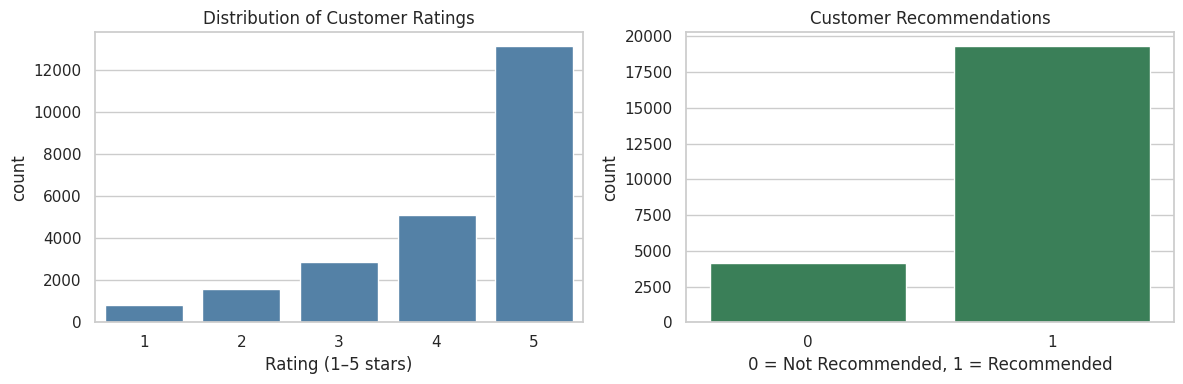

Recommendation percentages:
Recommended IND
1    82.24
0    17.76
Name: proportion, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=df,
    x="Rating",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Distribution of Customer Ratings")
axes[0].set_xlabel("Rating (1–5 stars)")

sns.countplot(
    data=df,
    x="Recommended IND",
    ax=axes[1],
    color="seagreen"
)

axes[1].set_title("Customer Recommendations")
axes[1].set_xlabel("0 = Not Recommended, 1 = Recommended")

plt.tight_layout()
plt.show()

print("Recommendation percentages:")
print(
    df["Recommended IND"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

,Number_of_Reviews,Average_Rating,Recommendation_Rate
Department Name,,,
Tops,10468,4.17,81.52
Dresses,6319,4.15,80.82
Bottoms,3799,4.29,85.13
Intimate,1735,4.28,85.01
Jackets,1032,4.26,83.62
Trend,119,3.82,73.95


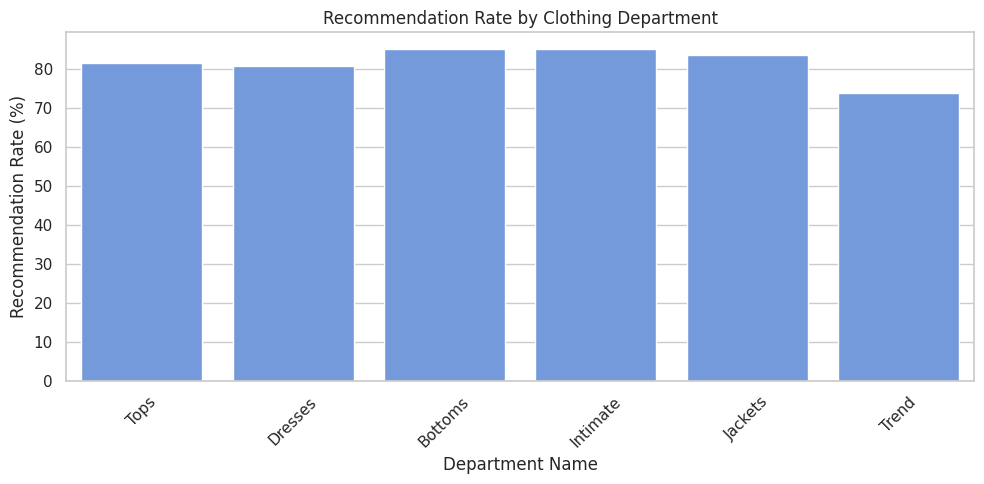

In [5]:
department_summary = (
    df.groupby("Department Name")
    .agg(
        Number_of_Reviews=("Rating", "count"),
        Average_Rating=("Rating", "mean"),
        Recommendation_Rate=("Recommended IND", "mean")
    )
    .sort_values("Number_of_Reviews", ascending=False)
)

department_summary["Recommendation_Rate"] *= 100

display(department_summary.round(2))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=department_summary.reset_index(),
    x="Department Name",
    y="Recommendation_Rate",
    color="cornflowerblue"
)

plt.title("Recommendation Rate by Clothing Department")
plt.ylabel("Recommendation Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Data Preprocessing**

We prepared the reviews by converting text to lowercase, removing URLs and unnecessary characters, and standardizing spaces.

We also corrected a spelling error in the product categories and removed an unnecessary index column.

Finally, we kept important words like "not" because they can change the meaning of a review.

In [6]:
df_clean = df.copy()

print("Original rows:", len(df_clean))

# Remove rows with missing review text
df_clean = df_clean.dropna(subset=["Review Text"]).copy()

# Remove blank review texts
df_clean["Review Text"] = df_clean["Review Text"].astype(str).str.strip()
df_clean = df_clean[df_clean["Review Text"] != ""].copy()

# Remove exact duplicate reviews
df_clean = df_clean.drop_duplicates(subset=["Review Text"])

print("Rows after cleaning:", len(df_clean))

# Simple and explainable NLP preprocessing
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_clean["clean_review"] = df_clean["Review Text"].apply(clean_text)

# Remove texts that became empty after cleaning
df_clean = df_clean[df_clean["clean_review"] != ""].copy()

# Prediction target:
# 1 = customer recommends product
# 0 = customer does not recommend product
df_clean["sentiment"] = df_clean["Recommended IND"].astype(int)

# Calculate review length
df_clean["review_length"] = (
    df_clean["clean_review"].str.split().str.len()
)

display(
    df_clean[
        ["Review Text", "clean_review", "sentiment", "review_length"]
    ].head()
)

print("Final dataset size:", len(df_clean))

Original rows: 23486
Rows after cleaning: 22634


,Review Text,clean_review,sentiment,review_length
0,Absolutely wonderful - silky and sexy and comf...,absolutely wonderful silky and sexy and comfor...,1,7
1,Love this dress! it's sooo pretty. i happene...,love this dress it's sooo pretty i happened to...,1,62
2,I had such high hopes for this dress and reall...,i had such high hopes for this dress and reall...,0,97
3,"I love, love, love this jumpsuit. it's fun, fl...",i love love love this jumpsuit it's fun flirty...,1,22
4,This shirt is very flattering to all due to th...,this shirt is very flattering to all due to th...,1,36


Final dataset size: 22634


In [23]:
# Fix spelling error in Division Name
df_clean["Division Name"] = df_clean["Division Name"].replace(
    "Initmates", "Intimates"
)

# Remove unnecessary index column
df_clean = df_clean.drop(columns=["Unnamed: 0"], errors="ignore")

# Verify corrections
print("Division names:")
print(df_clean["Division Name"].value_counts(dropna=False))

print("\nColumns after cleaning:")
print(df_clean.columns.tolist())

Division names:
Division Name
General           13363
General Petite     7835
Intimates          1423
NaN                  13
Name: count, dtype: int64

Columns after cleaning:
['Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name', 'clean_review', 'sentiment', 'review_length']


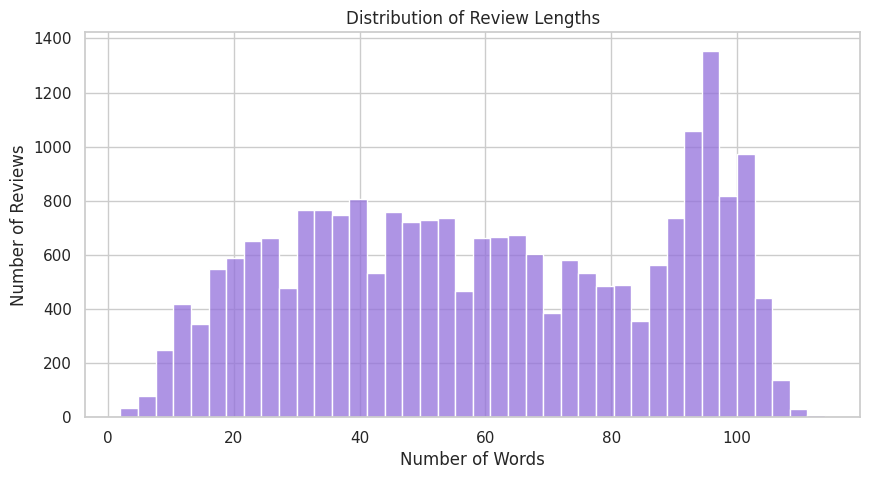

count    22634.000000
mean        59.872272
std         28.338828
min          2.000000
25%         36.000000
50%         59.000000
75%         88.000000
max        114.000000
Name: review_length, dtype: float64


In [7]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["review_length"],
    bins=40,
    color="mediumpurple"
)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.show()

print(df_clean["review_length"].describe())

**Model Training**

We divided our data into 80% for training and 20% for testing.

We used TF-IDF to convert the reviews into numbers that the computer can understand.

Then we compared two models: Naive Bayes and Logistic Regression.

In [8]:
X = df_clean["clean_review"]
y = df_clean["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

Training samples: 18107
Test samples: 4527

Training class distribution:
sentiment
1    0.819
0    0.181
Name: proportion, dtype: float64


In [9]:
# Baseline: always predicts the most frequent class
baseline = DummyClassifier(strategy="most_frequent")

# Model 1: TF-IDF + Naive Bayes
nb_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2,
        stop_words=None
    )),
    ("classifier", MultinomialNB())
])

# Model 2: TF-IDF + Logistic Regression
lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2,
        stop_words=None
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the models
baseline.fit(X_train, y_train)
nb_model.fit(X_train, y_train)
lr_model.fit(X_train, y_train)

print("All models trained successfully!")

All models trained successfully!


**Model Comparison**

Both models achieved 87.8% accuracy.

However, Logistic Regression was much better at identifying dissatisfied customers, detecting 85% compared to only 44% with Naive Bayes.

That's why we chose Logistic Regression for our application.

,Model,Accuracy,Precision (Negative),Recall (Negative),F1 (Negative),Macro F1
0,Majority Baseline,0.819,0.000,0.000,0.000,0.450
1,Naive Bayes,0.878,0.794,0.438,0.564,0.747
2,Logistic Regression,0.878,0.617,0.852,0.716,0.819


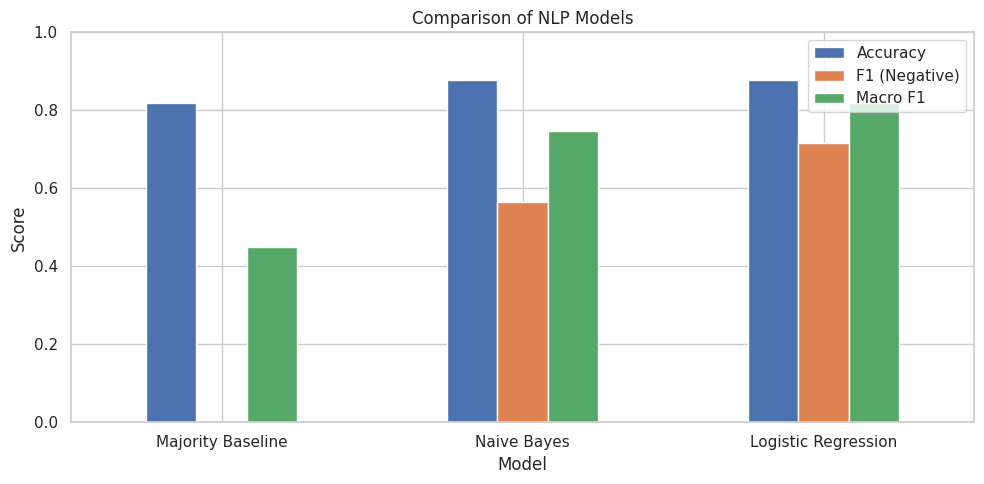

In [10]:
models = {
    "Majority Baseline": baseline,
    "Naive Bayes": nb_model,
    "Logistic Regression": lr_model
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Negative)": precision_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "Recall (Negative)": recall_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "F1 (Negative)": f1_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

results_df.set_index("Model")[
    ["Accuracy", "F1 (Negative)", "Macro F1"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Comparison of NLP Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Results & Limitations**

Our model correctly classified 87.8% of the test reviews.

However, it sometimes makes mistakes when customers mention both positive and negative things in the same review.

This shows that our model is useful, but not perfect.

Classification Report:
                 precision    recall  f1-score   support

Not Recommended       0.62      0.85      0.72       820
    Recommended       0.96      0.88      0.92      3707

       accuracy                           0.88      4527
      macro avg       0.79      0.87      0.82      4527
   weighted avg       0.90      0.88      0.88      4527



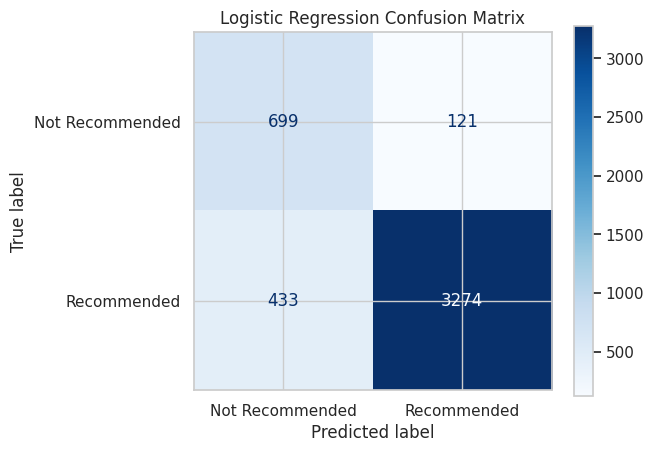

In [11]:
y_pred = lr_model.predict(X_test)

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=[
        "Not Recommended",
        "Recommended"
    ],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=[
        "Not Recommended",
        "Recommended"
    ],
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

In [12]:
error_analysis = df_clean.loc[X_test.index, [
    "Review Text",
    "Rating",
    "Recommended IND",
    "Department Name"
]].copy()

error_analysis["Predicted"] = y_pred

errors = error_analysis[
    error_analysis["Recommended IND"] !=
    error_analysis["Predicted"]
]

print("Number of incorrect predictions:", len(errors))

print("\nExamples of incorrect predictions:")
display(errors.head(10))

Number of incorrect predictions: 554

Examples of incorrect predictions:


,Review Text,Rating,Recommended IND,Department Name,Predicted
10657,"I was so excited to get the dress, it's extrem...",5,1,Dresses,0
21036,I have to agree with people who are saying thi...,3,1,Dresses,0
11970,I grabbed this during a 20% off sale so i will...,4,1,Tops,0
1962,"Okay, i get the idea of the loose swing dresse...",4,1,Dresses,0
5629,"This dress looked so cute on the model, but un...",3,1,Dresses,0
5320,"In theory, this dress was perfect for me. the ...",4,1,Dresses,0
1118,I ordered these as i was curious of hte fit on...,4,1,Bottoms,0
6113,When i first saw this dress i was in love. i a...,4,1,Dresses,0
16409,I loved this skirt but it was slightly too sma...,4,1,Bottoms,0
5666,"I'm 5'3"" and 120 lbs. i ordered a m and it was...",3,1,Tops,0


,Word,Count
0,fit,1326
1,fabric,1244
2,size,1210
3,look,965
4,it's,964
5,love,928
6,small,909
7,i'm,908
8,ordered,824
9,wear,755


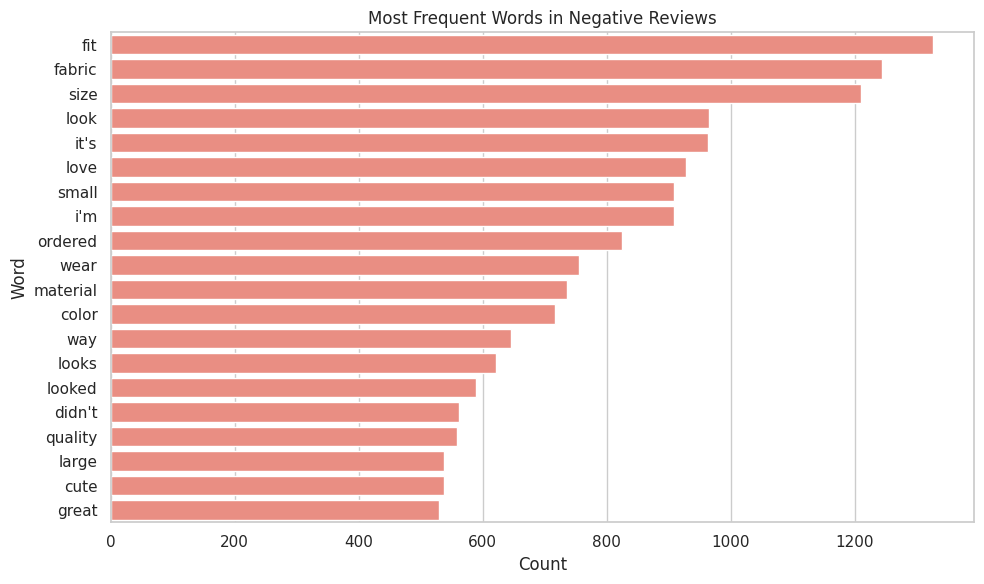

In [13]:
negative_reviews = df_clean[
    df_clean["sentiment"] == 0
]["clean_review"]

# Stopwords used only for keyword analysis
stopwords = set(ENGLISH_STOP_WORDS)

# Add very generic clothing-review terms
stopwords.update([
    "dress", "shirt", "top", "item",
    "really", "just", "like", "would"
])

all_words = []

for review in negative_reviews:
    words = review.split()

    for word in words:
        if word not in stopwords and len(word) > 2:
            all_words.append(word)

word_counts = Counter(all_words)

top_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Count"]
)

display(top_words)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_words,
    x="Count",
    y="Word",
    color="salmon"
)

plt.title("Most Frequent Words in Negative Reviews")
plt.tight_layout()
plt.show()

,Word,Count
0,fit,1326
1,fabric,1244
2,size,1210
3,look,965
4,love,928
5,small,909
6,wear,755
7,material,736
8,color,717
9,way,645


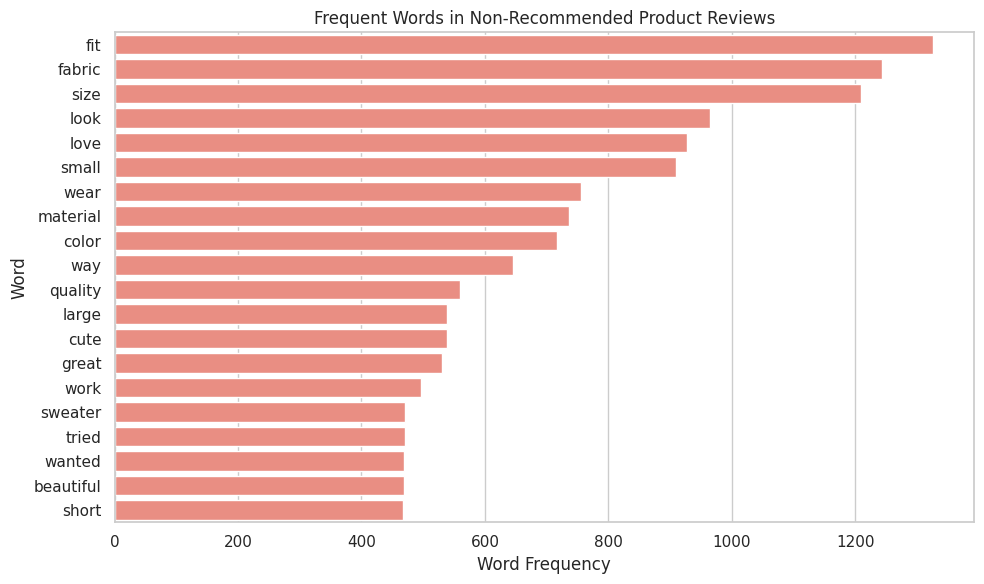

In [17]:
# Additional words that do not help identify complaint themes
extra_stopwords = {
    "it's", "i'm", "don't", "didn't", "doesn't",
    "i've", "i'd", "can't", "isn't",
    "really", "just", "like", "would",
    "looked", "looks", "ordered"
}

stopwords.update(extra_stopwords)

all_words = []

for review in negative_reviews:
    words = review.split()

    for word in words:
        if word not in stopwords and len(word) > 2:
            all_words.append(word)

word_counts = Counter(all_words)

top_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Count"]
)

display(top_words)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_words,
    x="Count",
    y="Word",
    color="salmon"
)

plt.title("Frequent Words in Non-Recommended Product Reviews")
plt.xlabel("Word Frequency")
plt.tight_layout()
plt.show()

In [18]:
sample_reviews = [
    "I love the quality and the fit is absolutely perfect!",
    "The material is cheap and the sizing is completely wrong.",
    "The color is beautiful but the fabric is uncomfortable."
]

for review in sample_reviews:

    cleaned = clean_text(review)

    prediction = lr_model.predict([cleaned])[0]
    probabilities = lr_model.predict_proba([cleaned])[0]

    label = (
        "Recommended" if prediction == 1
        else "Not Recommended"
    )

    confidence = probabilities[
        list(lr_model.classes_).index(prediction)
    ]

    print("Review:", review)
    print("Prediction:", label)
    print(f"Model probability: {confidence:.2%}")
    print("-" * 50)

Review: I love the quality and the fit is absolutely perfect!
Prediction: Recommended
Model probability: 89.77%
--------------------------------------------------
Review: The material is cheap and the sizing is completely wrong.
Prediction: Not Recommended
Model probability: 96.39%
--------------------------------------------------
Review: The color is beautiful but the fabric is uncomfortable.
Prediction: Not Recommended
Model probability: 84.12%
--------------------------------------------------


In [24]:
# Choose between the two actual NLP models
candidate_results = results_df[
    results_df["Model"].isin([
        "Naive Bayes",
        "Logistic Regression"
    ])
]

best_model_name = candidate_results.sort_values(
    "F1 (Negative)",
    ascending=False
).iloc[0]["Model"]

best_model = models[best_model_name]

print("Selected model:", best_model_name)

# Save NLP model
joblib.dump(best_model, "fashion_sentiment_model.joblib")

# Save cleaned dataset for the dashboard
df_clean.to_csv(
    "fashion_reviews_cleaned.csv",
    index=False
)

# Save evaluation results
results_df.to_csv(
    "model_evaluation.csv",
    index=False
)

print("Files saved successfully!")

Selected model: Logistic Regression
Files saved successfully!


In [25]:
files.download("fashion_sentiment_model.joblib")
files.download("fashion_reviews_cleaned.csv")
files.download("model_evaluation.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>